# 06 — ML: treinamento e avaliação do KNN

Código espelhado de `RETREINO/04_ml.py`. `tbl_ml` foi substituída por `desloc.gold.transacoes_ml`; `distancia` por `distancia_lalo`. O modelo, as métricas MAE/RMSE, os gráficos de erro e as 100 divisões repetidas seguem a sequência do professor.

### Treinamento

In [1]:
from sklearn.model_selection import train_test_split

df = spark.table("desloc.gold.transacoes_ml").toPandas()
X = df.drop(columns=["vlr_pago"])
Y = df["vlr_pago"]

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor

# Desabilitar o MLFLOW automatico do Databricks
import mlflow
mlflow.autolog(disable=True)

colunas_minmax = [
    'dia', 'dia_semana', 'mes', 'hora', 'distancia_lalo','latitude_origem',
    'longitude_origem', 'latitude_destino', 'longitude_destino'
]

preprocessador = ColumnTransformer(
    transformers=[
        ('drop', 'drop', ['periodo']),
        ('minmax', MinMaxScaler(), colunas_minmax)
    ],
    remainder='passthrough'  # mantém as outras colunas sem alteração
)

pipeline = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('knn', KNeighborsRegressor(n_neighbors=5))
])

pipeline.fit(X_train, y_train)

,steps,"[('preprocessamento', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('drop', ...), ('minmax', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [3]:
y_hat_train = pipeline.predict(X_train)
y_hat_test = pipeline.predict(X_test)

### Métricas

In [4]:
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

metrics = dict(
    mae_train = mean_absolute_error(y_train, y_hat_train),
    mae_test = mean_absolute_error(y_test, y_hat_test),
    rmse_train = root_mean_squared_error(y_train, y_hat_train),
    rmse_test = root_mean_squared_error(y_test, y_hat_test)
)

pd.DataFrame(metrics, index=[0])

,mae_train,mae_test,rmse_train,rmse_test
0,1.658386,1.516952,2.02963,2.007336


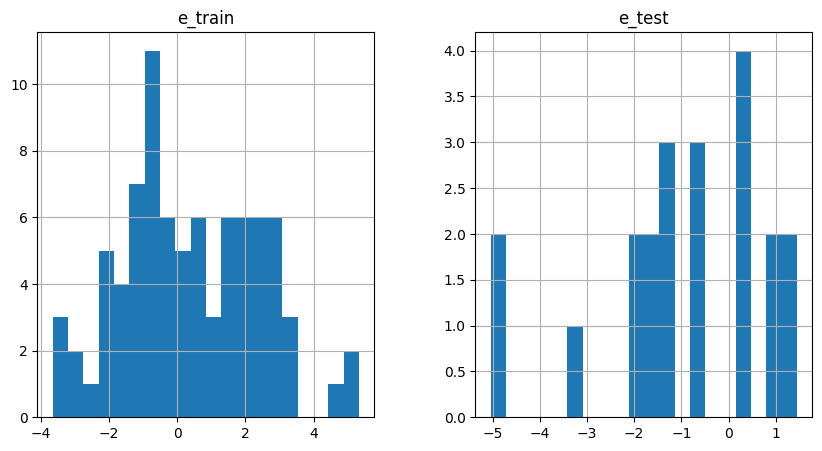

In [5]:
e_train = y_train - y_hat_train
e_test = y_test - y_hat_test

df_plot = pd.DataFrame({
    'e_train': e_train,
    'e_test': e_test,
    'y_train': y_train,
    'y_test': y_test,
})

df_plot[["e_train", "e_test"]].hist(bins=20, figsize=(10, 5));

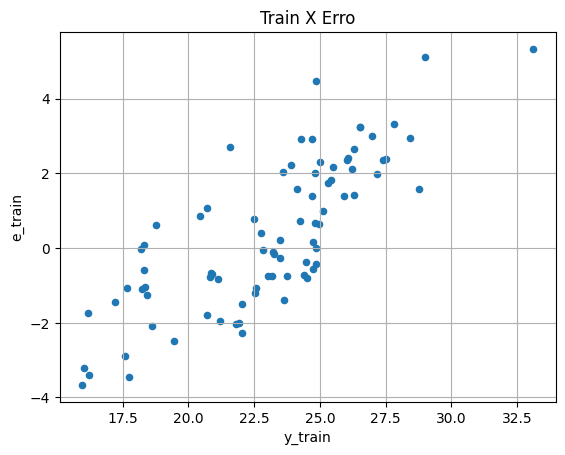

In [6]:
df_plot[["e_train", "y_train"]].plot(
    kind="scatter", x="y_train", y="e_train",
    grid=True, title="Train X Erro"
);

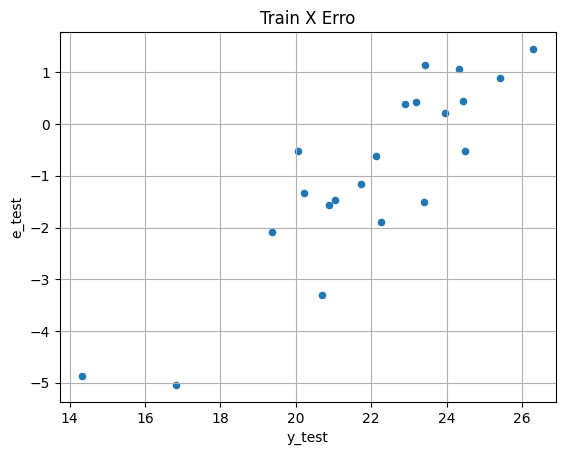

In [7]:
df_plot[["e_test", "y_test"]].plot(
    kind="scatter", x="y_test", y="e_test",
    grid=True, title="Train X Erro"
);

In [8]:
def print_metrics(y_train, y_test, y_hat_train, y_hat_test):
    metrics = dict(
        mae_train = mean_absolute_error(y_train, y_hat_train),
        mae_test = mean_absolute_error(y_test, y_hat_test),
        rmse_train = root_mean_squared_error(y_train, y_hat_train),
        rmse_test = root_mean_squared_error(y_test, y_hat_test)
    )

    return pd.DataFrame(metrics, index=[0])

In [9]:
dfs = []
for i in range(0, 100):
    X_train, X_test, y_train, y_test = train_test_split(
        X, Y,
        test_size=0.2,
    )

    pipeline.fit(X_train, y_train)

    y_hat_train = pipeline.predict(X_train)
    y_hat_test = pipeline.predict(X_test)
    dfs.append(print_metrics(y_train, y_test, y_hat_train, y_hat_test))

In [10]:
pd.concat(dfs).describe()

,mae_train,mae_test,rmse_train,rmse_test
count,100.000000,100.000000,100.000000,100.000000
mean,1.520105,1.968818,1.952154,2.485667
std,0.100301,0.320054,0.130572,0.352428
min,1.287229,1.158857,1.654342,1.518840
25%,1.456078,1.784452,1.874571,2.316092
50%,1.521060,1.973238,1.973912,2.531330
75%,1.587355,2.181000,2.046431,2.734797
max,1.728313,2.664381,2.192988,3.208846


### Testando o Algoritmo

Interprete os valores produzidos nesta execução; os números do material do professor não são resultados desta base. Após o laço de 100 divisões, `y_test` e `y_hat_test` correspondem à última divisão, enquanto `metrics` guarda a primeira divisão.


In [11]:
m = pd.DataFrame(metrics, index=[0])
m.columns = ["Erro em Treino", "Erro em Teste", "Erro Penalizado em Treino", "Erro Penalizado em Teste"]
m

,Erro em Treino,Erro em Teste,Erro Penalizado em Treino,Erro Penalizado em Teste
0,1.658386,1.516952,2.02963,2.007336


In [12]:
print(f"Valor total real das corridas no teste: R$ {y_test.sum():.2f}")
print(f"Valor total previsto pelo algoritmo no teste: R$ {y_hat_test.sum():.2f}")

Valor total real das corridas no teste: R$ 462.04
Valor total previsto pelo algoritmo no teste: R$ 457.16


## Explicabilidade (XAI) e limite de negócio
Cabeçalho mantido para uma etapa futura, sem alterar o código da aula. As métricas aqui não comparam o KNN com o modelo atualmente em produção. As features de calendário vêm da entrega e precisam ser substituídas por informações disponíveis antes da cotação.